# Day 20 | Connect Python to a Local LLM

**KGP Talkie**

Use ChatOllama, invoke, streaming, and response metadata.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

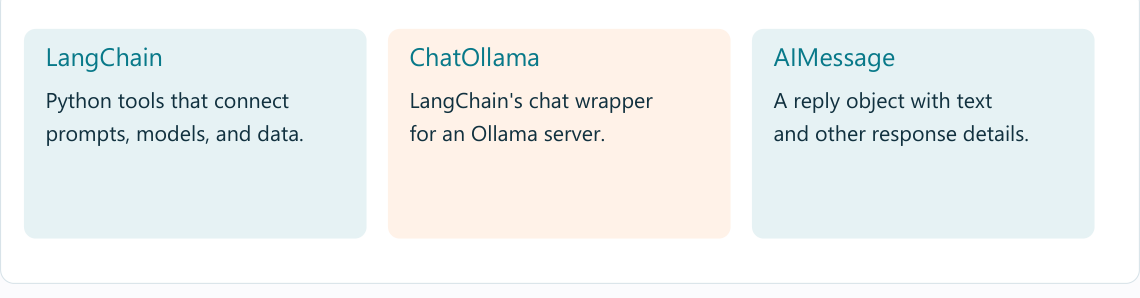

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [7]:
response = llm.invoke("Explain a Python dictionary in two short points.")

content contains the text. The response itself also has usage and run details.

In [8]:
print(response.content)

Here are two short points explaining a Python dictionary:

1. **Key-Value Pair Data Structure**: A Python dictionary is an unordered collection of key-value pairs, where each key is unique and maps to a specific value.
2. **Dynamic and Mutable**: Dictionaries are dynamic and mutable, meaning you can add or remove key-value pairs at any time, and their structure can change as needed.


Metadata can help inspect a run. Duration and token count are not a quality grade.

In [9]:
response.response_metadata

{'model': 'llama3.2',
 'created_at': '2026-10-09T07:41:29.4248816Z',
 'done': True,
 'done_reason': 'stop',
 'total_duration': 2616912800,
 'load_duration': 207437800,
 'prompt_eval_count': 35,
 'prompt_eval_duration': 71542000,
 'eval_count': 80,
 'eval_duration': 2333466000,
 'logprobs': None,
 'model_name': 'llama3.2',
 'model_provider': 'ollama'}

In [10]:
parts = []

The loop displays each chunk as it arrives and stores it for the full reply.

In [11]:
for chunk in llm.stream("Explain a Python list in one sentence."):
    parts.append(chunk.content)
    print(chunk.content, end="", flush=True)

A

 Python

 list

 is

 a

...

 and

 manipulation

 of

 elements

.

join combines text chunks in the same order. This is a fresh question, not a saved reply.

In [12]:
full_text = "".join(parts)
print(full_text)

A Python list is a data structure that stores a collection of items, which can be of any data type, including strings, integers, floats, and other lists, and allows for efficient addition, removal, and manipulation of elements.

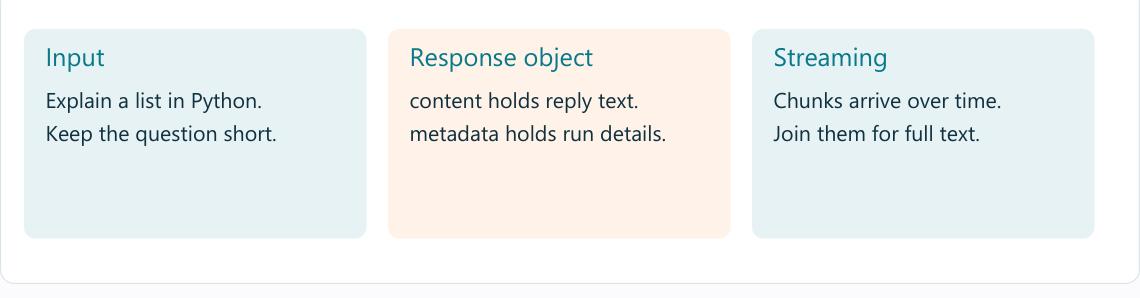

## Try a fresh input

Stream a different prompt and join the chunks. Compare the two ways of receiving a reply.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-getting-started).